In [1]:
!pip install pandas numpy matplotlib scikit-learn tqdm seaborn

# UNIVERSAL 168-Hour Extrapolation (All Components)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from sklearn.linear_model import LinearRegression
from tqdm import tqdm

# Find all device files
file_paths = sorted(glob.glob('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_*.csv'))
print(f"Found {len(file_paths)} device files.")

results = []

for file_path in tqdm(file_paths, desc="Processing Devices"):
    try:
        # Load data for this specific device
        df = pd.read_csv(file_path, usecols=['Device_ID', 'Aging_Hours', 'RDS_on_Ohm', 'Baseline_RDS_Ohm'])
        df = df.dropna(subset=['Aging_Hours', 'RDS_on_Ohm']).sort_values('Aging_Hours')
        
        if len(df) < 2:
            continue
            
        device_id = str(df['Device_ID'].iloc[0])
        baseline_rds = df['Baseline_RDS_Ohm'].iloc[0]
        max_hour = df['Aging_Hours'].max()
        
        # Fit Linear Model
        X_train = df[['Aging_Hours']]
        y_train = df['RDS_on_Ohm']
        
        model = LinearRegression()
        model.fit(X_train, y_train)
        
        # Forecast 168h
        X_future = pd.DataFrame({'Aging_Hours': [168.0]})
        pred_168h = model.predict(X_future)[0]
        
        # Calculate degradation percentage
        if baseline_rds != 0:
            deg_pct = ((pred_168h - baseline_rds) / baseline_rds) * 100
        else:
            deg_pct = np.nan
            
        # Flag component if degradation > 5% (Example threshold)
        is_flagged = deg_pct > 5.0
        
        results.append({
            'Device_ID': device_id,
            'Max_Observed_Hour': max_hour,
            'Baseline_RDS': baseline_rds,
            'Forecast_168h_RDS': pred_168h,
            'Degradation_Pct': deg_pct,
            'Flagged': is_flagged
        })
    except Exception as e:
        print(f"Error processing {file_path}: {e}")

res_df = pd.DataFrame(results)
print("Finished forecasting for all components.")


Found 42 device files.


Processing Devices: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 42/42 [00:01<00:00, 38.63it/s]

Finished forecasting for all components.


--- UNIVERSAL FORECAST SUMMARY ---
Total Components Evaluated: 42
Components FLAGGED (>5% projected degradation): 37
Components PASS: 5


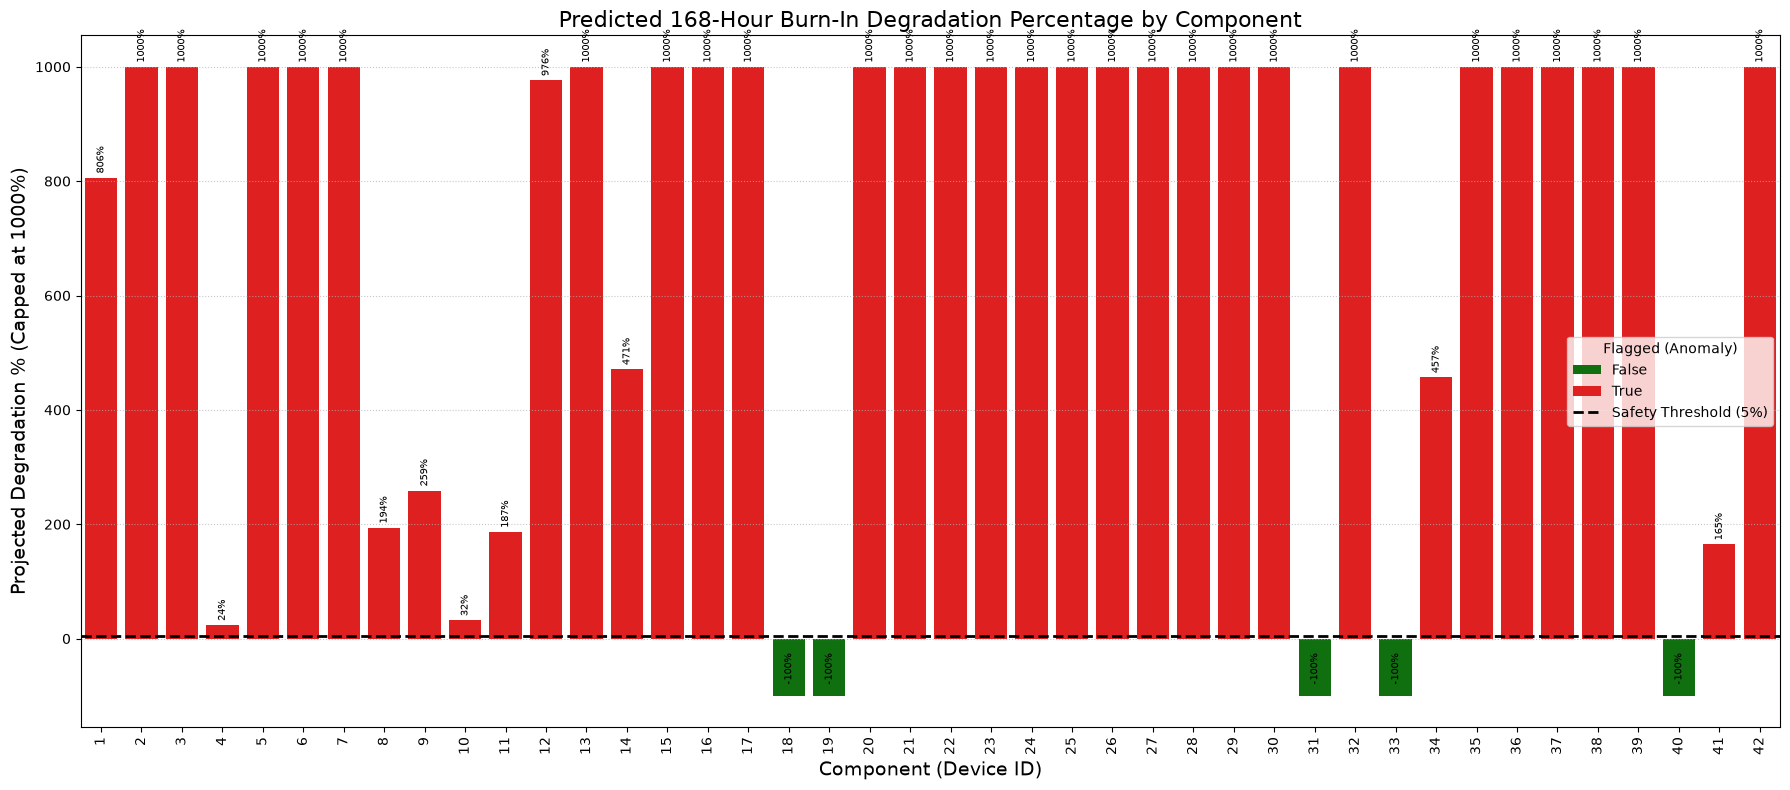

In [3]:
# Summary Statistics
print("--- UNIVERSAL FORECAST SUMMARY ---")
print(f"Total Components Evaluated: {len(res_df)}")
print(f"Components FLAGGED (>5% projected degradation): {res_df['Flagged'].sum()}")
print(f"Components PASS: {len(res_df) - res_df['Flagged'].sum()}")

# To prevent crazy outliers from ruining the graph, let's cap the visualization at 1000%
res_df['Display_Degradation_Pct'] = res_df['Degradation_Pct'].clip(upper=1000, lower=-100)

plt.figure(figsize=(18, 8))
ax = sns.barplot(data=res_df, x='Device_ID', y='Display_Degradation_Pct', hue='Flagged', palette={True: 'red', False: 'green'}, dodge=False)

plt.axhline(y=5.0, color='black', linestyle='--', linewidth=2, label='Safety Threshold (5%)')

# Annotate values
for p in ax.patches:
    height = p.get_height()
    if height != 0 and not np.isnan(height):
        ax.annotate(f'{height:.0f}%', 
                    (p.get_x() + p.get_width() / 2., height if height > 0 else 0),
                    ha='center', va='bottom' if height > 0 else 'top',
                    xytext=(0, 3 if height > 0 else -10), 
                    textcoords='offset points',
                    fontsize=7, rotation=90)

plt.title('Predicted 168-Hour Burn-In Degradation Percentage by Component', fontsize=16)
plt.xlabel('Component (Device ID)', fontsize=14)
plt.ylabel('Projected Degradation % (Capped at 1000%)', fontsize=14)
plt.xticks(rotation=90)
plt.legend(title='Flagged (Anomaly)')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()
